In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import pandas as pd
import numpy as np
import joblib

Создаю описание для встречного регрессора. Так как его реализации в виде модулей торча нет, всю логику надо будет прописать в форварде

input_dim - размерность входного вектора
num_neurons - количество нейронов в слое Кохонена
output_dim - размерность слоя Гроссберга (выходного)

In [2]:
class CounterPropagationRegressor(nn.Module):
    def __init__(self, input_dim, num_neurons, output_dim=1):
        super().__init__()
        # Веса слоя Кохонена (кластеризация пространства признаков)
        self.kohonen_weights = nn.Parameter(torch.randn(num_neurons, input_dim) * 0.01)
        # Веса слоя Гроссберга (линейное отображение кластеров в целевую переменную)
        self.grossberg_weights = nn.Parameter(torch.randn(output_dim, num_neurons) * 0.01)

    def forward(self, x):
        # x shape: (batch_size, input_dim)
        # Вычисление евклидовых расстояний до нейронов Кохонена
        # ||x - w||^2 = ||x||^2 + ||w||^2 - 2 * x * w^T
        x_sq = (x ** 2).sum(dim=1, keepdim=True)
        w_sq = (self.kohonen_weights ** 2).sum(dim=1, keepdim=True).T
        dist = x_sq + w_sq - 2 * torch.matmul(x, self.kohonen_weights.T)

        # Жесткая конкуренция (Winner-Take-All)
        winner_indices = torch.argmin(dist, dim=1)

        # Активация побеждающего нейрона (one-hot вектор)
        batch_size = x.size(0)
        z = torch.zeros(batch_size, self.kohonen_weights.size(0), device=x.device)
        z.scatter_(1, winner_indices.unsqueeze(1), 1.0)

        # Выход слоя Гроссберга
        out = torch.matmul(z, self.grossberg_weights.T)
        return out

In [4]:
train_daily = pd.read_csv('train_daily.csv')
val_daily = pd.read_csv('val_daily.csv')
test_daily = pd.read_csv('test_daily.csv')

# scaler_daily_X = joblib.load('scaler_daily_X.pkl')
scaler_daily_y = joblib.load('scaler_daily_y.pkl')

Подготовка данных для модели

In [5]:
target_col = 'T'
feature_cols = [col for col in train_daily.columns if col != target_col]

X_train_daily = train_daily[feature_cols]
y_train_daily = train_daily[[target_col]]

X_val_daily = val_daily[feature_cols]
y_val_daily = val_daily[[target_col]]

X_test_daily = test_daily[feature_cols]
y_test_daily = test_daily[[target_col]]

train_daily_tensor = TensorDataset(torch.tensor(X_train_daily.values, dtype=torch.float32), torch.tensor(y_train_daily.values, dtype=torch.float32))
val_daily_tensor = TensorDataset(torch.tensor(X_val_daily.values, dtype=torch.float32), torch.tensor(y_val_daily.values, dtype=torch.float32))

train_daily_loader = DataLoader(train_daily_tensor, batch_size=64, shuffle=True)
val_daily_loader = DataLoader(val_daily_tensor, batch_size=64, shuffle=False)

Инициализация модели, лосса, оптимизатора и планировщика

In [9]:
input_dim = X_train_daily.shape[1]
num_neurons = 64
output_dim = 1

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_counter_prop_daily = CounterPropagationRegressor(input_dim=input_dim, num_neurons=num_neurons, output_dim=output_dim).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model_counter_prop_daily.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

Сам цикл обучения с динамической отрисовкой лосса на валидации и обучении

In [7]:
import matplotlib.pyplot as plt
from IPython.display import clear_output

def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler=None, epochs=50, device='cpu'):
    model.to(device)
    train_losses, val_losses = [], []

    for epoch in range(epochs):
        # Тренировка
        model.train()
        train_loss = 0.0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)

            optimizer.zero_grad()
            predictions = model(batch_x)
            loss = criterion(predictions, batch_y)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * batch_x.size(0)

        train_loss /= len(train_loader.dataset)
        train_losses.append(train_loss)

        # Валидация
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)

                predictions = model(batch_x)
                loss = criterion(predictions, batch_y)
                val_loss += loss.item() * batch_x.size(0)

        val_loss /= len(val_loader.dataset)
        val_losses.append(val_loss)

        # Планировщик
        if scheduler is not None:
            scheduler.step(val_loss)

        # График
        clear_output(wait=True)
        plt.figure(figsize=(10, 4))
        plt.plot(train_losses, label='Train Loss', color='blue')
        plt.plot(val_losses, label='Val Loss', color='orange', linestyle='--')
        plt.yscale('log')
        plt.title(f'Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}')
        plt.xlabel('Эпоха')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True)
        plt.show()

    return model, train_losses, val_losses

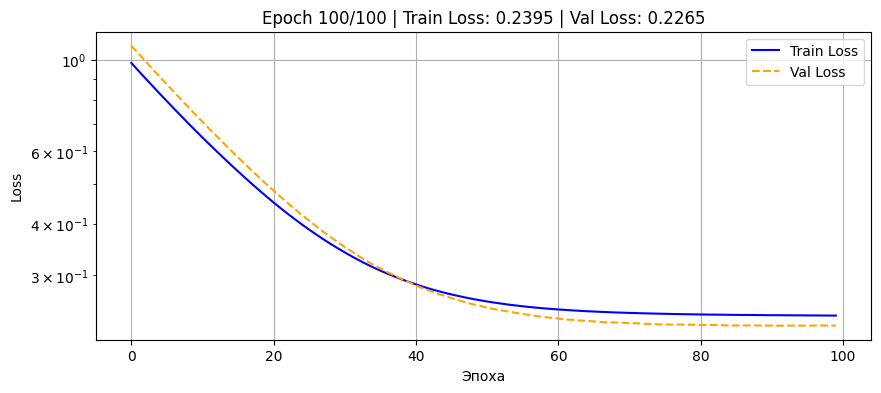

In [10]:
trained_model_counter_prop_daily, train_hist, val_hist = train_model(
    model=model_counter_prop_daily,
    train_loader=train_daily_loader,
    val_loader=val_daily_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=100,
    device=device
)

Проверка метрик

In [11]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Берем готовые масштабированные признаки и таргет из датафрейма
X_test_daily_vals = X_test_daily.values
y_test_daily_vals = y_test_daily.values

# 2. Получаем предсказания модели (они тоже в масштабе скейлера)
trained_model_counter_prop_daily.eval()
with torch.no_grad():
    X_test_tensor = torch.tensor(X_test_daily_vals, dtype=torch.float32)
    y_pred_daily = trained_model_counter_prop_daily(X_test_tensor.to(device)).cpu().numpy()

# 3. Возвращаем истинные и предсказанные значения в исходный масштаб для адекватных метрик
y_test_orig = scaler_daily_y.inverse_transform(y_test_daily_vals)
y_pred_orig = scaler_daily_y.inverse_transform(y_pred_daily)

# 4. Расчет метрик в реальных единицах
test_mse = mean_squared_error(y_test_orig, y_pred_orig)
test_mae = mean_absolute_error(y_test_orig, y_pred_orig)
test_r2 = r2_score(y_test_orig, y_pred_orig)

print(f"Test MSE: {test_mse:.4f}")
print(f"Test MAE: {test_mae:.4f}")
print(f"Test R2:  {test_r2:.4f}")

Test MSE: 41.0626
Test MAE: 5.1255
Test R2:  0.6176


График для сравнения реальной температуры и предсказанной моделью

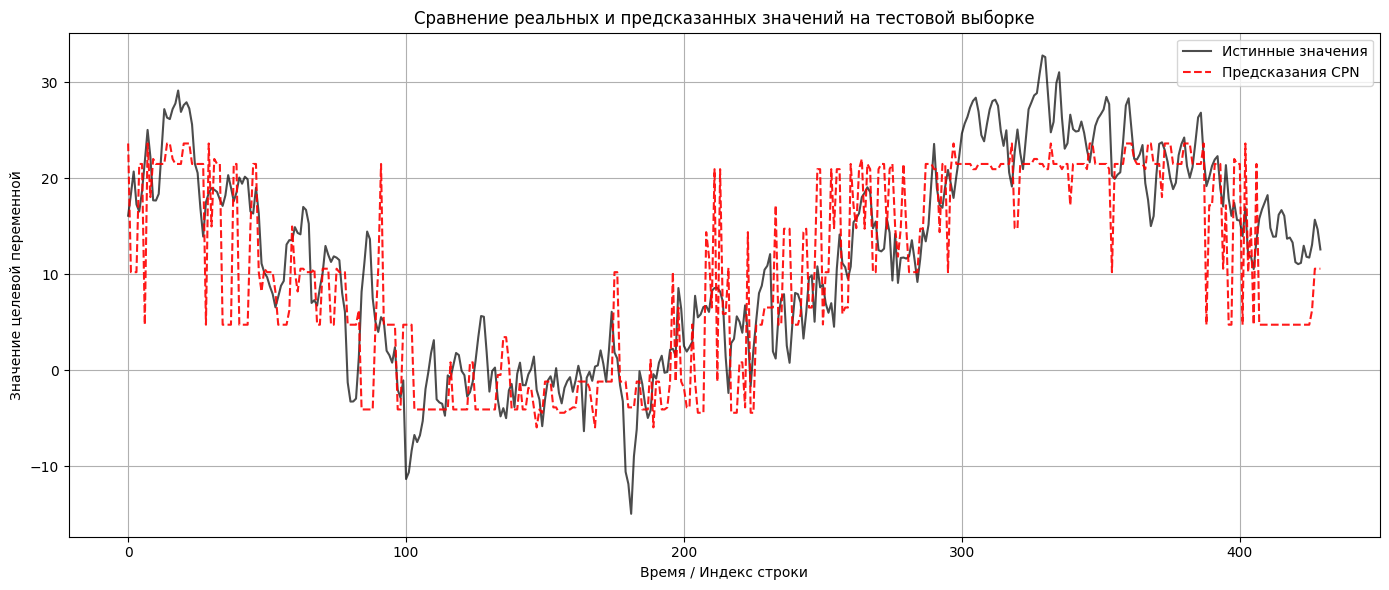

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

x_axis = range(len(y_test_orig))

plt.plot(x_axis, y_test_orig, label='Истинные значения', color='black', alpha=0.7, linewidth=1.5)
plt.plot(x_axis, y_pred_orig, label='Предсказания CPN', color='red', linestyle='--', alpha=0.9, linewidth=1.5)

plt.title('Сравнение реальных и предсказанных значений на тестовой выборке')
plt.xlabel('Время / Индекс строки')
plt.ylabel('Значение целевой переменной')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Модель смогла уловить только общую сезонность, но она ограничена снизу и сверху изза чего сильно падает точность

Теперь будет подготовка датасета для рекуррентных моделей: нужно перевести данные в 3д формат: нужно убрать лаги (они теперь не нужны тк модели рекуррентные), а в качестве признака использовать таргет. НО: утечки данных не будет тк модель предсказывает следующий день: функция create_sequnces для таргета i + seq_len ставит признаки до i + seq_len не включительно

In [13]:
X_train_daily.drop(columns=[i for i in X_train_daily.columns if 'lag' in i])

,P0,P,U,DD_Ветер,DD_Переменное направление,DD_Штиль,day_of_year,day_of_week_sin,day_of_week_cos,month_sin,month_cos
0,0.547059,0.513578,-0.863426,0.791667,0.000000,0.208333,1.064796,0.000000,1.000000,-0.866025,0.500000
1,0.306471,0.309382,0.182785,1.000000,0.000000,0.000000,1.073964,0.781831,0.623490,-0.866025,0.500000
2,-0.093102,-0.054967,0.560140,1.000000,0.000000,0.000000,1.083132,0.974928,-0.222521,-0.866025,0.500000
3,-0.469888,-0.430778,0.912928,0.913043,0.000000,0.086957,1.092299,0.433884,-0.900969,-0.866025,0.500000
4,-1.145498,-1.104642,0.332529,1.000000,0.000000,0.000000,1.101467,-0.433884,-0.900969,-0.866025,0.500000
...,...,...,...,...,...,...,...,...,...,...,...
1999,-0.426197,-0.539766,-1.594176,1.000000,0.000000,0.000000,-0.328668,0.433884,-0.900969,0.500000,-0.866025
2000,-0.865164,-0.938816,-0.467103,0.958333,0.020833,0.020833,-0.319500,-0.433884,-0.900969,0.500000,-0.866025
2001,0.584955,0.513085,-1.428807,1.000000,0.000000,0.000000,-0.310333,-0.974928,-0.222521,0.500000,-0.866025
2002,1.502728,1.402765,-1.774867,1.000000,0.000000,0.000000,-0.301165,-0.781831,0.623490,0.500000,-0.866025


In [14]:
X_train_daily_concated = pd.concat([X_train_daily.drop(columns=[i for i in X_train_daily.columns if 'lag' in i]), y_train_daily], axis=1)
X_train_daily_concated.head(8)

,P0,P,U,DD_Ветер,DD_Переменное направление,DD_Штиль,day_of_year,day_of_week_sin,day_of_week_cos,month_sin,month_cos,T
0,0.547059,0.513578,-0.863426,0.791667,0.0,0.208333,1.064796,0.000000,1.000000,-0.866025,0.5,0.111944
1,0.306471,0.309382,0.182785,1.000000,0.0,0.000000,1.073964,0.781831,0.623490,-0.866025,0.5,-0.196076
2,-0.093102,-0.054967,0.560140,1.000000,0.0,0.000000,1.083132,0.974928,-0.222521,-0.866025,0.5,-0.437591
3,-0.469888,-0.430778,0.912928,0.913043,0.0,0.086957,1.092299,0.433884,-0.900969,-0.866025,0.5,-0.317366
4,-1.145498,-1.104642,0.332529,1.000000,0.0,0.000000,1.101467,-0.433884,-0.900969,-0.866025,0.5,-0.070068
5,-0.233797,-0.223129,-0.076771,1.000000,0.0,0.000000,1.110634,-0.974928,-0.222521,-0.866025,0.5,-0.084068
6,0.306471,0.280688,-0.230508,1.000000,0.0,0.000000,1.119802,-0.781831,0.623490,-0.866025,0.5,0.118945
7,-0.354091,-0.375942,0.278622,1.000000,0.0,0.000000,1.128969,0.000000,1.000000,-0.866025,0.5,0.367461


In [15]:
X_val_daily_concated = pd.concat([X_val_daily.drop(columns=[i for i in X_val_daily.columns if 'lag' in i]), y_val_daily], axis=1)
X_test_daily_concated = pd.concat([X_test_daily.drop(columns=[i for i in X_test_daily.columns if 'lag' in i]), y_test_daily], axis=1)

In [16]:
def create_sequences(X_scaled, y_scaled, seq_len):
    xs, ys = [], []
    for i in range(len(X_scaled) - seq_len):
        xs.append(X_scaled[i : (i + seq_len)])
        ys.append(y_scaled[i + seq_len])
    return np.array(xs), np.array(ys)

# Задаем длину последовательности
seq_len = 7

X_train = X_train_daily_concated.values
y_train = y_train_daily.values
X_val = X_val_daily_concated.values
y_val = y_val_daily.values
X_test = X_test_daily_concated.values
y_test = y_test_daily.values

# Применяем для train, val, test
X_train_3d_daily, y_train_3d_daily = create_sequences(X_train, y_train, seq_len)
X_val_3d_daily, y_val_3d_daily     = create_sequences(X_val, y_val, seq_len)
X_test_3d_daily, y_test_3d_daily   = create_sequences(X_test, y_test, seq_len)

# Конвертируем в тензоры PyTorch
train_dataset = torch.utils.data.TensorDataset(torch.tensor(X_train_3d_daily, dtype=torch.float32), torch.tensor(y_train_3d_daily, dtype=torch.float32))
val_dataset   = torch.utils.data.TensorDataset(torch.tensor(X_val_3d_daily, dtype=torch.float32), torch.tensor(y_val_3d_daily, dtype=torch.float32))
test_dataset  = torch.utils.data.TensorDataset(torch.tensor(X_test_3d_daily, dtype=torch.float32), torch.tensor(y_test_3d_daily, dtype=torch.float32))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader   = torch.utils.data.DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader  = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False)

In [17]:
# Выведет матрицу размером (seq_len, feature_dim) для первого окна
print("Признаки (X) для первого примера:\n", X_train_3d_daily[0])

# Выведет одно число - целевое значение, следующее сразу за этим окном
print("Таргет (y) для первого примера:\n", y_train_3d_daily[0])

Признаки (X) для первого примера:
 [[ 0.54705892  0.51357841 -0.8634256   0.79166667  0.          0.20833333
   1.06479647  0.          1.         -0.8660254   0.5         0.11194416]
 [ 0.30647099  0.30938235  0.18278539  1.          0.          0.
   1.07396399  0.78183148  0.6234898  -0.8660254   0.5        -0.1960756 ]
 [-0.09310194 -0.05496748  0.56014012  1.          0.          0.
   1.08313152  0.97492791 -0.22252093 -0.8660254   0.5        -0.43759109]
 [-0.46988844 -0.43077759  0.91292816  0.91304348  0.          0.08695652
   1.09229905  0.43388374 -0.90096887 -0.8660254   0.5        -0.31736599]
 [-1.14549824 -1.104642    0.33252933  1.          0.          0.
   1.10146658 -0.43388374 -0.90096887 -0.8660254   0.5        -0.07006752]
 [-0.23379663 -0.22312894 -0.07677077  1.          0.          0.
   1.1106341  -0.97492791 -0.22252093 -0.8660254   0.5        -0.08406841]
 [ 0.30647099  0.28068813 -0.23050788  1.          0.          0.
   1.11980163 -0.78183148  0.6234898 

Да все правильно сформировано

Далее описания оставшихся трех нейронок:
- Один слой RNN
- Один слой LSTM
- Два слоя LSTM

In [18]:
# 1. Один слой RNN
class SimpleRNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim=1):
        super().__init__()
        self.rnn = nn.RNN(input_dim, hidden_dim, num_layers=1, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        # x shape: (batch_size, seq_len, input_dim)
        out, _ = self.rnn(x)
        # Берем выход только с последнего временного шага
        out = self.fc(out[:, -1, :])
        return out

# 2. Один слой LSTM
class SimpleLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim=1):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers=1, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return out

# 3. Два слоя LSTM (с Dropout для регуляризации)
class DeepLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim=1, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=2,
            batch_first=True,
            dropout=dropout
        )
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return out

Сначала RNN

In [19]:
input_dim = X_train_3d_daily.shape[2]
hidden_dim = 64

rnn_model = SimpleRNN(input_dim=input_dim, hidden_dim=hidden_dim, output_dim=1).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(rnn_model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

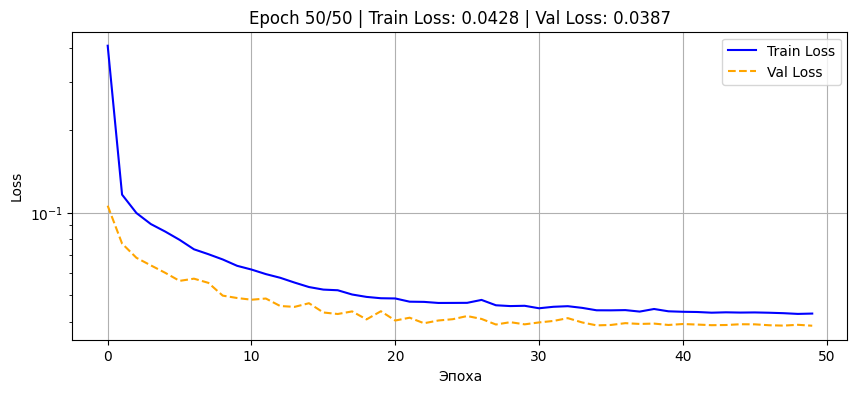

In [20]:
trained_rnn, train_hist, val_hist = train_model(
    model=rnn_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=50,
    device=device
)

In [21]:
def evaluate_recurrent_model(model, test_loader, scaler_y, device='cpu'):
    model.eval()
    predictions = []
    actuals = []

    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            batch_x = batch_x.to(device)
            outputs = model(batch_x)

            predictions.extend(outputs.cpu().numpy())
            actuals.extend(batch_y.numpy())

    # Превращаем в numpy-массивы
    y_pred_scaled = np.array(predictions)
    y_true_scaled = np.array(actuals)

    # Возвращаем в оригинальный масштаб
    y_pred_orig = scaler_y.inverse_transform(y_pred_scaled)
    y_true_orig = scaler_y.inverse_transform(y_true_scaled)

    # Считаем метрики
    mse = mean_squared_error(y_true_orig, y_pred_orig)
    mae = mean_absolute_error(y_true_orig, y_pred_orig)
    r2 = r2_score(y_true_orig, y_pred_orig)

    print(f"Test MSE: {mse:.4f}")
    print(f"Test MAE: {mae:.4f}")
    print(f"Test R2:  {r2:.4f}")

    return y_true_orig, y_pred_orig

In [22]:
def plot_predictions(y_true_orig, y_pred_orig, model_name="RNN/LSTM"):
    plt.figure(figsize=(14, 6))

    plt.plot(y_true_orig, label='Истинные значения', color='black', alpha=0.7, linewidth=1.5)
    plt.plot(y_pred_orig, label=f'Предсказания ({model_name})', color='red', linestyle='--', alpha=0.8, linewidth=1.5)

    plt.title(f'Сравнение реальных и предсказанных значений — {model_name}')
    plt.xlabel('Индуцированный индекс / Время')
    plt.ylabel('Значение целевой переменной')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Test MSE: 5.4308
Test MAE: 1.7671
Test R2:  0.9499


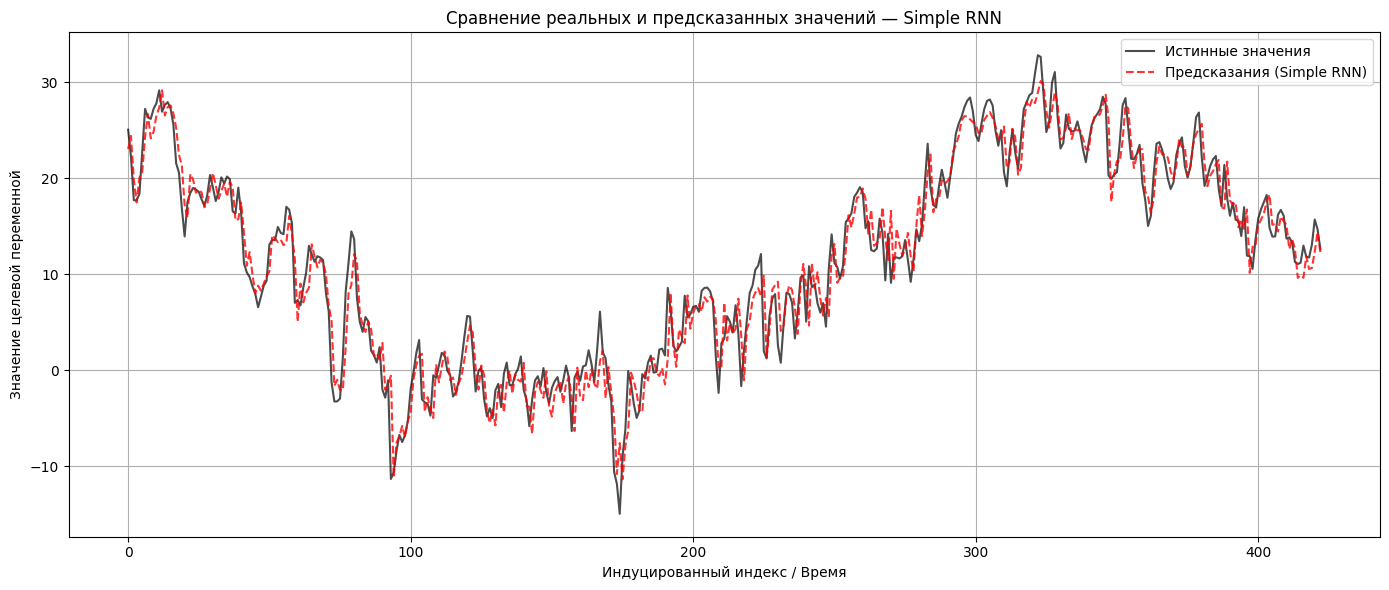

In [23]:
# Получаем метрики и массивы для графика
y_true, y_pred = evaluate_recurrent_model(trained_rnn, test_loader, scaler_daily_y, device=device)

# Рисуем график
plot_predictions(y_true, y_pred, model_name="Simple RNN")

Почти идеальный результат. Причем обучалась модель заметно быстрее

In [24]:
input_dim = X_train_3d_daily.shape[2]
hidden_dim = 64

lstm_model = SimpleLSTM(input_dim=input_dim, hidden_dim=hidden_dim, output_dim=1).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

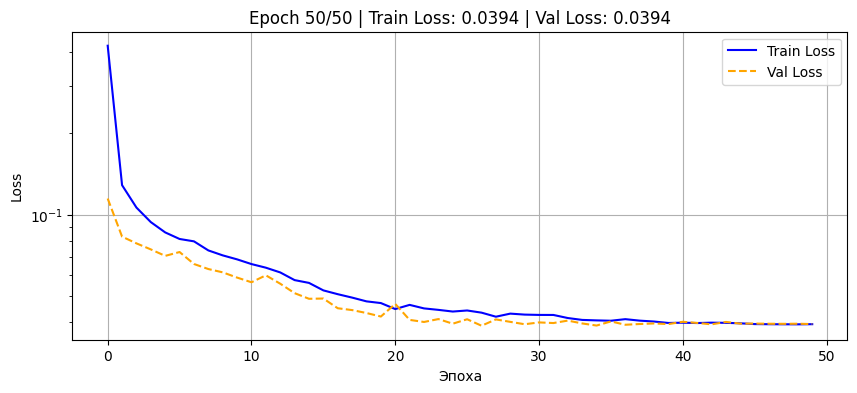

In [25]:
trained_lstm, train_hist, val_hist = train_model(
    model=lstm_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=50,
    device=device
)

Test MSE: 5.2492
Test MAE: 1.7832
Test R2:  0.9515


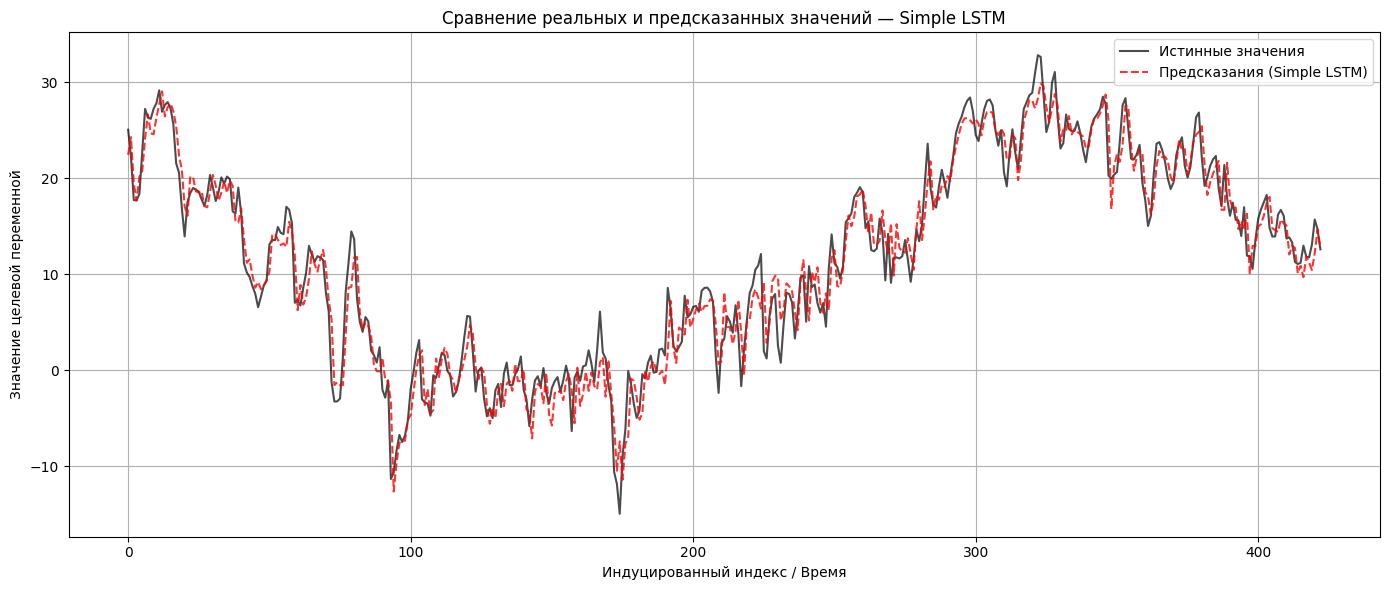

In [26]:
y_true, y_pred = evaluate_recurrent_model(trained_lstm, test_loader, scaler_daily_y, device=device)
plot_predictions(y_true, y_pred, model_name="Simple LSTM")

In [27]:
input_dim = X_train_3d_daily.shape[2]
hidden_dim = 64

deep_lstm_model = DeepLSTM(input_dim=input_dim, hidden_dim=hidden_dim, output_dim=1).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(deep_lstm_model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

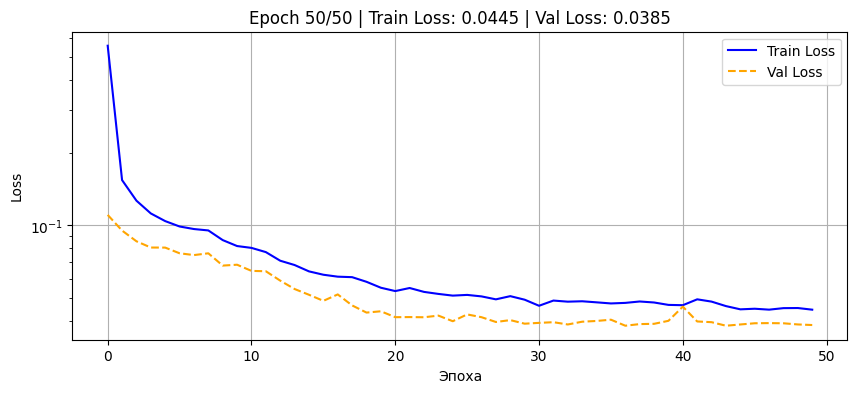

In [28]:
trained_deep_lstm, train_hist, val_hist = train_model(
    model=deep_lstm_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=50,
    device=device
)

Test MSE: 5.2144
Test MAE: 1.7681
Test R2:  0.9519


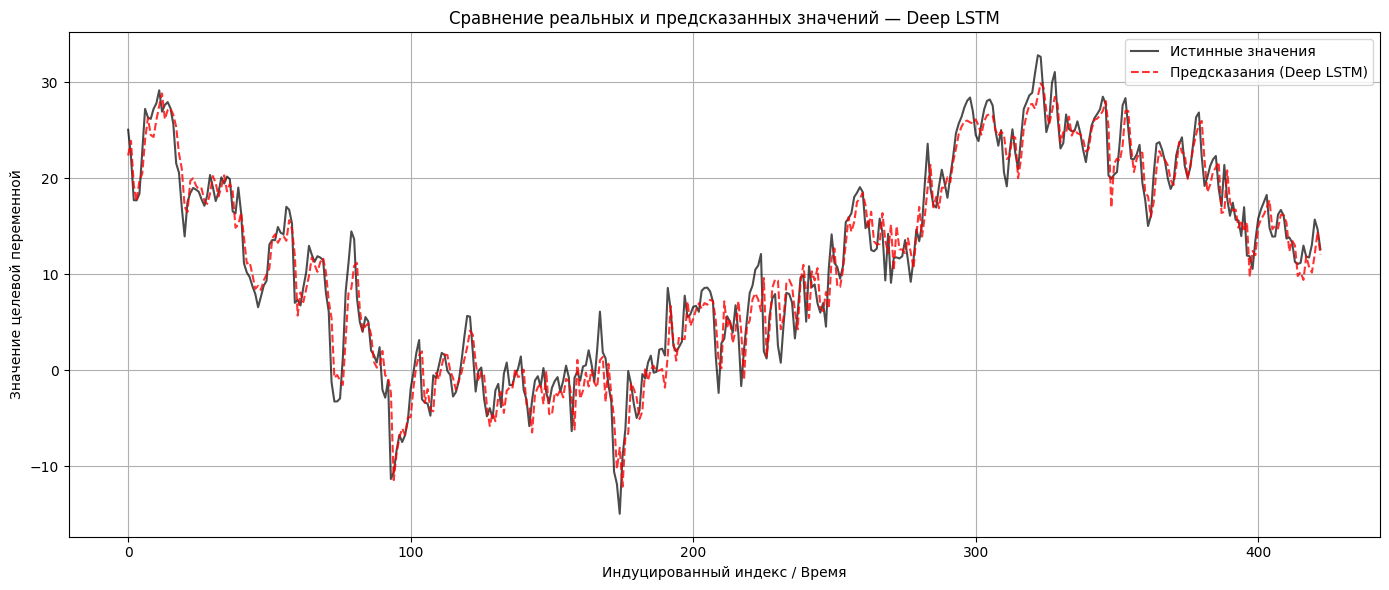

In [29]:
y_true, y_pred = evaluate_recurrent_model(trained_deep_lstm, test_loader, scaler_daily_y, device=device)
plot_predictions(y_true, y_pred, model_name="Deep LSTM")

Теперь аналогично все проделать для датасета с еженедельным отслеживанием средней температуры

In [30]:
train_weekly = pd.read_csv('train_weekly.csv')
val_weekly = pd.read_csv('val_weekly.csv')
test_weekly = pd.read_csv('test_weekly.csv')

# scaler_daily_X = joblib.load('scaler_daily_X.pkl')
scaler_weekly_y = joblib.load('scaler_weekly_y.pkl')

In [31]:
target_col = 'T'
feature_cols = [col for col in train_weekly.columns if col != target_col]

X_train_weekly = train_weekly[feature_cols]
y_train_weekly = train_weekly[[target_col]]

X_val_weekly = val_weekly[feature_cols]
y_val_weekly = val_weekly[[target_col]]

X_test_weekly = test_weekly[feature_cols]
y_test_weekly = test_weekly[[target_col]]

train_weekly_tensor = TensorDataset(torch.tensor(X_train_weekly.values, dtype=torch.float32), torch.tensor(y_train_weekly.values, dtype=torch.float32))
val_weekly_tensor = TensorDataset(torch.tensor(X_val_weekly.values, dtype=torch.float32), torch.tensor(y_val_weekly.values, dtype=torch.float32))

train_weekly_loader = DataLoader(train_weekly_tensor, batch_size=64, shuffle=True)
val_weekly_loader = DataLoader(val_weekly_tensor, batch_size=64, shuffle=False)

In [38]:
input_dim = X_train_weekly.shape[1]
num_neurons = 64
output_dim = 1

model_counter_prop_weekly = CounterPropagationRegressor(input_dim=input_dim, num_neurons=num_neurons, output_dim=output_dim).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model_counter_prop_weekly.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

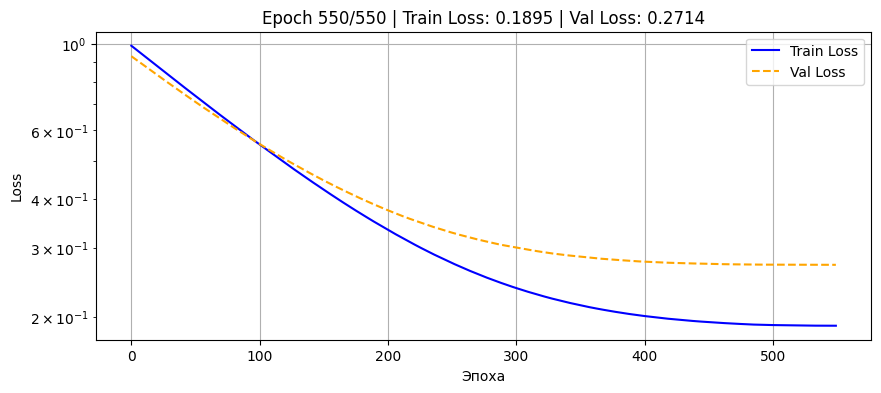

In [39]:
trained_model_counter_prop_weekly, train_hist, val_hist = train_model(
    model=model_counter_prop_weekly,
    train_loader=train_weekly_loader,
    val_loader=val_weekly_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=550,
    device=device
)

In [40]:
X_test_weekly_vals = X_test_weekly.values
y_test_weekly_vals = y_test_weekly.values

trained_model_counter_prop_weekly.eval()
with torch.no_grad():
    X_test_tensor = torch.tensor(X_test_weekly_vals, dtype=torch.float32)
    y_pred_weekly = trained_model_counter_prop_weekly(X_test_tensor.to(device)).cpu().numpy()

y_test_orig = scaler_weekly_y.inverse_transform(y_test_weekly_vals)
y_pred_orig = scaler_weekly_y.inverse_transform(y_pred_weekly)

test_mse = mean_squared_error(y_test_orig, y_pred_orig)
test_mae = mean_absolute_error(y_test_orig, y_pred_orig)
test_r2 = r2_score(y_test_orig, y_pred_orig)

print(f"Test MSE: {test_mse:.4f}")
print(f"Test MAE: {test_mae:.4f}")
print(f"Test R2:  {test_r2:.4f}")

Test MSE: 37.4985
Test MAE: 4.6223
Test R2:  0.6417


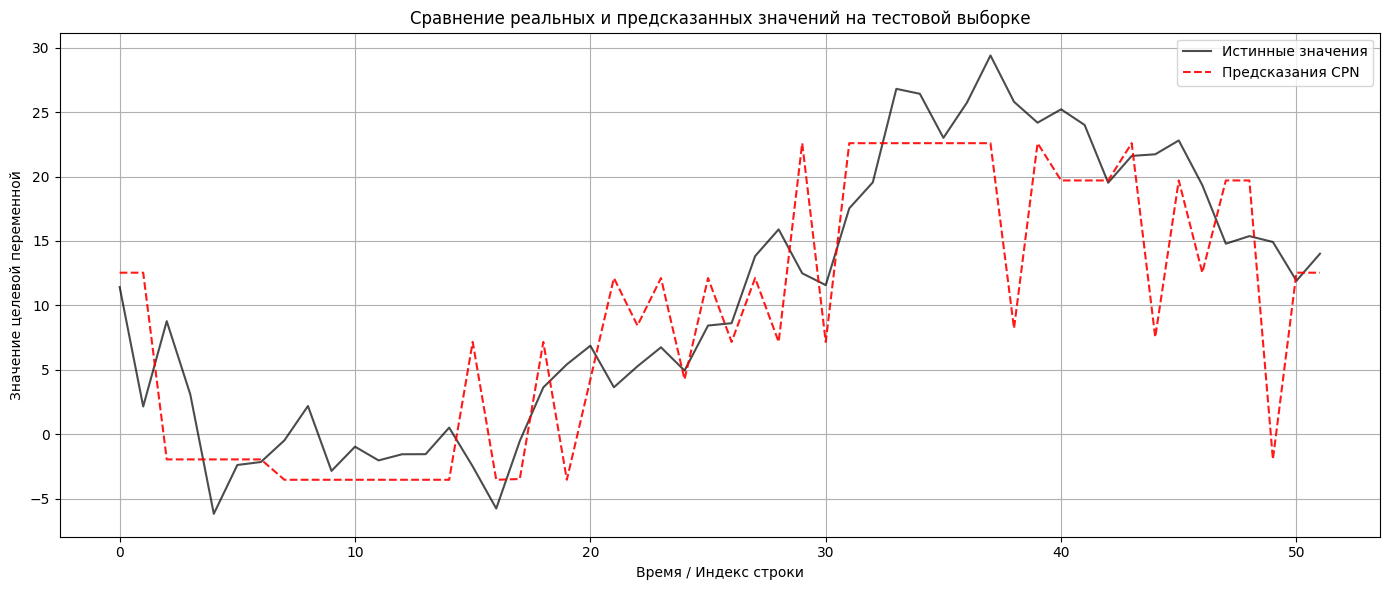

In [41]:
plt.figure(figsize=(14, 6))

x_axis = range(len(y_test_orig))

plt.plot(x_axis, y_test_orig, label='Истинные значения', color='black', alpha=0.7, linewidth=1.5)
plt.plot(x_axis, y_pred_orig, label='Предсказания CPN', color='red', linestyle='--', alpha=0.9, linewidth=1.5)

plt.title('Сравнение реальных и предсказанных значений на тестовой выборке')
plt.xlabel('Время / Индекс строки')
plt.ylabel('Значение целевой переменной')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

В целом на недельных данных модель показала себя так же: ограниченность снизу и сверху, запоминание только общих тенденций

In [44]:
X_train_weekly_concated = pd.concat([X_train_weekly.drop(
    columns=[i for i in X_train_weekly.columns if 'lag' in i and i not in ['lag_51', 'lag_52', 'lag_53']]), y_train_weekly], axis=1)
X_train_weekly_concated.head(13)

,P0,P,U,DD_Ветер,DD_Переменное направление,DD_Штиль,week_sin,week_cos,lag_51,lag_52,lag_53,T
0,1.144028,1.108149,0.525423,0.952381,0.017857,0.029762,-8.854560e-01,0.464723,-0.078626,-0.140762,0.340454,-0.258775
1,0.585193,0.551162,1.050317,0.993976,0.006024,0.000000,-8.229839e-01,0.568065,-0.198069,-0.069319,-0.135593,-0.008939
2,0.404311,0.377857,0.909048,1.000000,0.000000,0.000000,-7.485107e-01,0.663123,-0.601597,-0.189428,-0.063928,0.009760
3,0.201222,0.213836,0.871540,1.000000,0.000000,0.000000,-6.631227e-01,0.748511,-0.845237,-0.595207,-0.184409,-0.251628
4,1.464644,1.449257,0.187235,0.994048,0.005952,0.000000,-5.680647e-01,0.822984,-0.370834,-0.840205,-0.591450,-0.582447
5,-0.759946,-0.648982,0.950576,1.000000,0.000000,0.000000,-4.647232e-01,0.885456,-0.432447,-0.363157,-0.837210,-0.691069
6,-1.384450,-1.226579,1.034992,0.994048,0.000000,0.005952,-3.546049e-01,0.935016,-1.610896,-0.425113,-0.358679,-0.810140
7,-0.834083,-0.642548,1.170389,1.000000,0.000000,0.000000,-2.393157e-01,0.970942,-1.951701,-1.610134,-0.420827,-1.335468
8,1.428733,1.468284,0.986505,0.994048,0.005952,0.000000,-1.205367e-01,0.992709,-1.450456,-1.952840,-1.609533,-1.032728
9,1.892042,1.892988,1.426241,1.000000,0.000000,0.000000,6.432491e-16,1.000000,-0.952314,-1.448799,-1.953304,-0.903055


In [45]:
X_val_weekly_concated = pd.concat([X_val_weekly.drop(
    columns=[i for i in X_val_weekly.columns if 'lag' in i and i not in ['lag_51', 'lag_52', 'lag_53']]), y_val_weekly], axis=1)

X_test_weekly_concated = pd.concat([X_test_weekly.drop(
    columns=[i for i in X_test_weekly.columns if 'lag' in i and i not in ['lag_51', 'lag_52', 'lag_53']]), y_test_weekly], axis=1)

In [46]:
seq_len = 12

X_train = X_train_weekly_concated.values
y_train = y_train_weekly.values
X_val = X_val_weekly_concated.values
y_val = y_val_weekly.values
X_test = X_test_weekly_concated.values
y_test = y_test_weekly.values

X_train_3d_weekly, y_train_3d_weekly = create_sequences(X_train, y_train, seq_len)
X_val_3d_weekly, y_val_3d_weekly     = create_sequences(X_val, y_val, seq_len)
X_test_3d_weekly, y_test_3d_weekly   = create_sequences(X_test, y_test, seq_len)

train_dataset = torch.utils.data.TensorDataset(torch.tensor(X_train_3d_weekly, dtype=torch.float32), torch.tensor(y_train_3d_weekly, dtype=torch.float32))
val_dataset   = torch.utils.data.TensorDataset(torch.tensor(X_val_3d_weekly, dtype=torch.float32), torch.tensor(y_val_3d_weekly, dtype=torch.float32))
test_dataset  = torch.utils.data.TensorDataset(torch.tensor(X_test_3d_weekly, dtype=torch.float32), torch.tensor(y_test_3d_weekly, dtype=torch.float32))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader   = torch.utils.data.DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader  = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False)

In [47]:
print("Признаки (X) для первого примера:\n", X_train_3d_weekly[0])
print("Таргет (y) для первого примера:\n", y_train_3d_weekly[0])

Признаки (X) для первого примера:
 [[ 1.14402754e+00  1.10814907e+00  5.25423050e-01  9.52380952e-01
   1.78571429e-02  2.97619048e-02 -8.85456026e-01  4.64723172e-01
  -7.86263594e-02 -1.40762468e-01  3.40454277e-01 -2.58775337e-01]
 [ 5.85192579e-01  5.51162438e-01  1.05031686e+00  9.93975904e-01
   6.02409639e-03  0.00000000e+00 -8.22983866e-01  5.68064747e-01
  -1.98068714e-01 -6.93190910e-02 -1.35592994e-01 -8.93895882e-03]
 [ 4.04310559e-01  3.77856922e-01  9.09048469e-01  1.00000000e+00
   0.00000000e+00  0.00000000e+00 -7.48510748e-01  6.63122658e-01
  -6.01597465e-01 -1.89427565e-01 -6.39275115e-02  9.75971146e-03]
 [ 2.01221656e-01  2.13836122e-01  8.71539783e-01  1.00000000e+00
   0.00000000e+00  0.00000000e+00 -6.63122658e-01  7.48510748e-01
  -8.45236822e-01 -5.95206762e-01 -1.84409382e-01 -2.51628016e-01]
 [ 1.46464411e+00  1.44925652e+00  1.87234983e-01  9.94047619e-01
   5.95238095e-03  0.00000000e+00 -5.68064747e-01  8.22983866e-01
  -3.70834377e-01 -8.40204876e-01 -5.

In [50]:
input_dim = X_train_3d_weekly.shape[2]
hidden_dim = 64

rnn_model = SimpleRNN(input_dim=input_dim, hidden_dim=hidden_dim, output_dim=1).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(rnn_model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

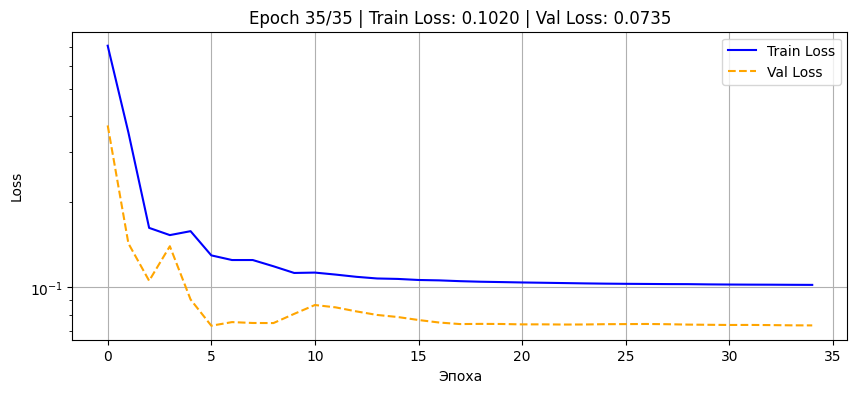

In [51]:
trained_rnn, train_hist, val_hist = train_model(
    model=rnn_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=35,
    device=device
)

Test MSE: 9.5047
Test MAE: 2.4984
Test R2:  0.8972


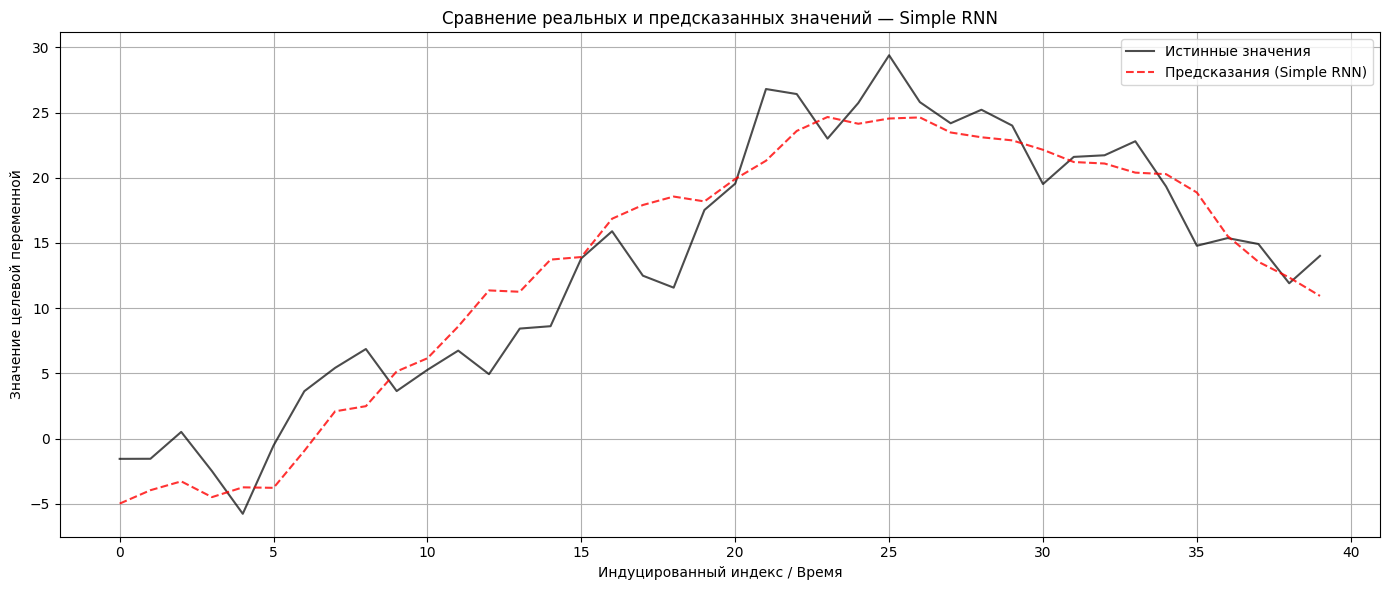

In [52]:
y_true, y_pred = evaluate_recurrent_model(trained_rnn, test_loader, scaler_weekly_y, device=device)
plot_predictions(y_true, y_pred, model_name="Simple RNN")

модель сильно хуже чем по дням но учитывая размер датасета результат все равно хороший

In [53]:
input_dim = X_train_3d_weekly.shape[2]
hidden_dim = 64

lstm_model = SimpleLSTM(input_dim=input_dim, hidden_dim=hidden_dim, output_dim=1).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

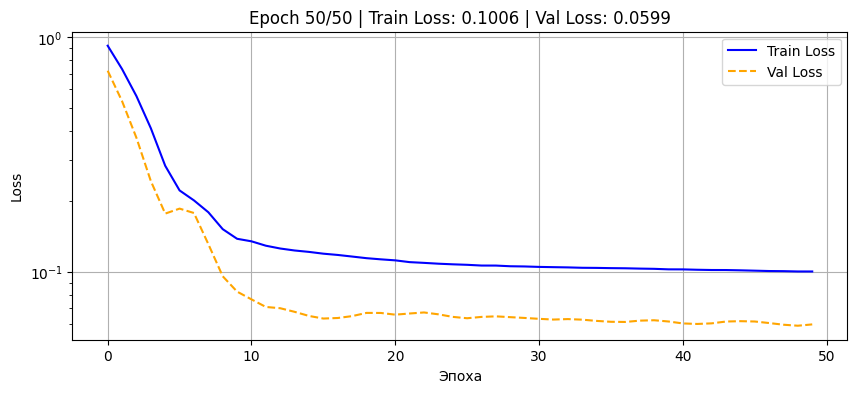

In [54]:
trained_lstm, train_hist, val_hist = train_model(
    model=lstm_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=50,
    device=device
)

Test MSE: 11.3390
Test MAE: 2.7705
Test R2:  0.8773


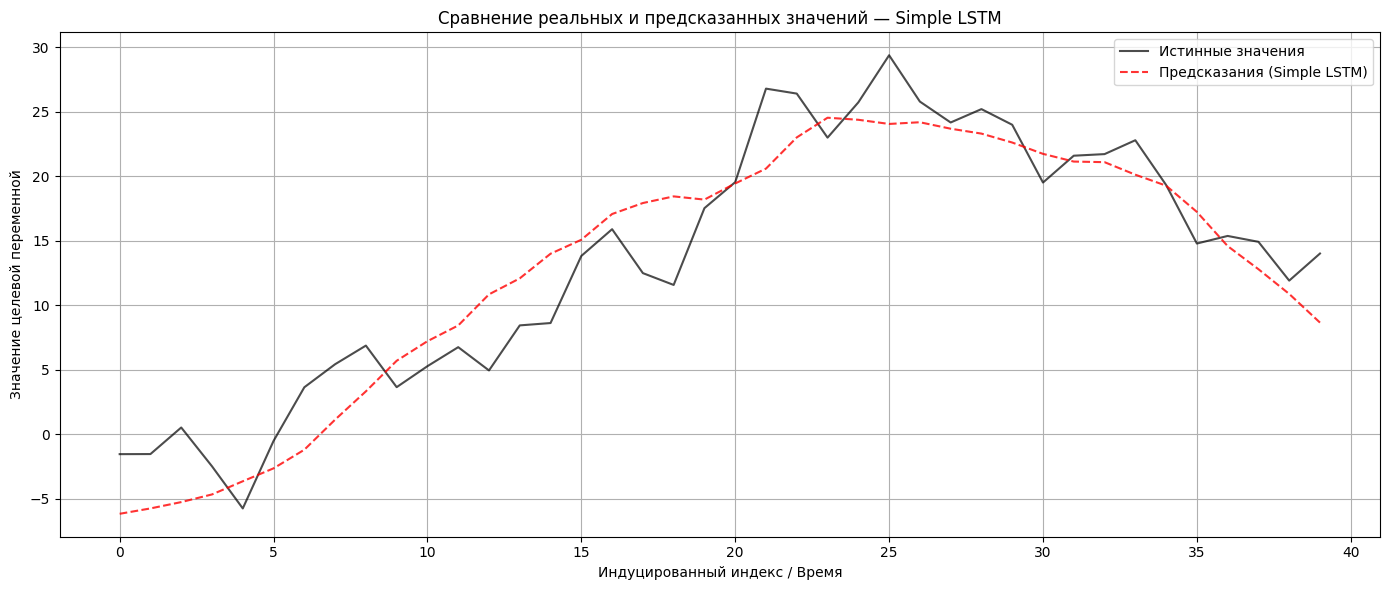

In [55]:
y_true, y_pred = evaluate_recurrent_model(trained_lstm, test_loader, scaler_weekly_y, device=device)
plot_predictions(y_true, y_pred, model_name="Simple LSTM")

В принципе как и RNN

In [58]:
deep_lstm_model = DeepLSTM(input_dim=input_dim, hidden_dim=hidden_dim, output_dim=1).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(deep_lstm_model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

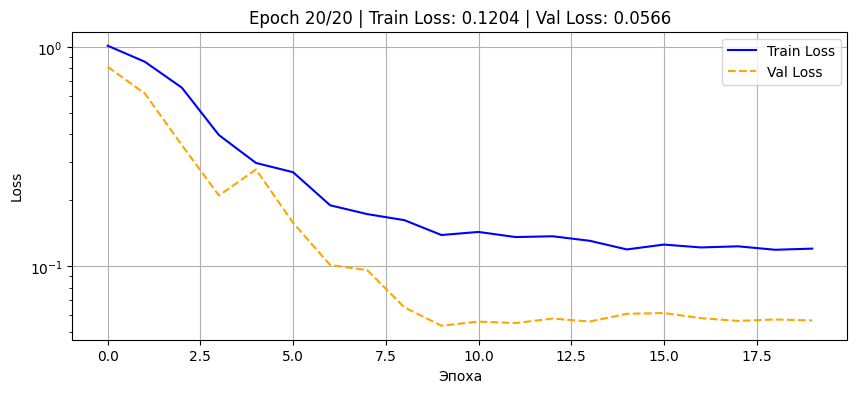

In [59]:
trained_deep_lstm, train_hist, val_hist = train_model(
    model=deep_lstm_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=20,
    device=device
)

Test MSE: 13.2445
Test MAE: 2.9811
Test R2:  0.8567


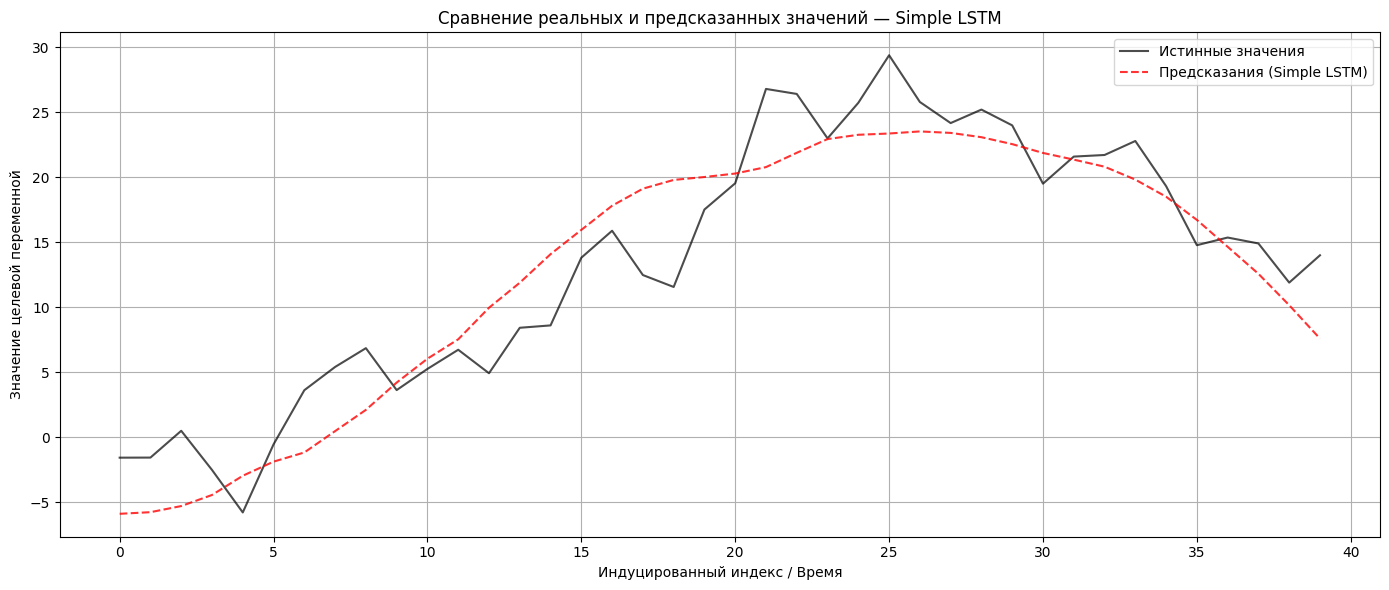

In [60]:
y_true, y_pred = evaluate_recurrent_model(trained_deep_lstm, test_loader, scaler_weekly_y, device=device)
plot_predictions(y_true, y_pred, model_name="Simple LSTM")

По итогу на малом количестве данных обычная RNN оказалась лучше всех